# 01 — Dataset inventory
Chạy từ bất kỳ thư mục làm việc nào. Mỗi dataset được audit độc lập; không ghi file. DeepPCB: `x1 y1 x2 y2 class_id` (pixel, ID 1–6); PKU: `class_id cx cy w h` (YOLO chuẩn hóa, ID 0–5). Các hàm ở ô code đầu tiên được dùng lại bởi bốn notebook tiếp theo.

In [1]:
from pathlib import Path
from collections import Counter
import math
import re
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

def project_root():
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / 'data' / 'raw' / 'DeepPCB').is_dir() and (base / 'scripts' / '01_inventory.ipynb').is_file():
            return base
    raise FileNotFoundError('Run from the project root or a directory inside it.')

ROOT = project_root()
DATASETS = {'DeepPCB': ('DeepPCB', 'xyxy_1based'), 'PKU': ('PKU-Market-PCB(Data enhanced version)', 'yolo_0based')}
SPLITS = ('train', 'valid', 'test')
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}

def audit_dataset(name):
    folder, fmt = DATASETS[name]
    base = ROOT / 'data' / 'raw' / folder
    classes = re.findall(r"['\"]([^'\"]+)['\"]", (base / 'Class.txt').read_text(encoding='utf-8-sig'))
    if not classes:
        raise ValueError(f'No classes in {base / "Class.txt"}')
    counts, class_counts, boxes, issues, images_by_class = [], [], [], [], {i: [] for i in range(len(classes))}
    per_image_rows = []
    for split in SPLITS:
        images_dir, labels_dir = base / split / 'images', base / split / 'labels'
        image_files = sorted(p for p in images_dir.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
        label_files = sorted(p for p in labels_dir.iterdir() if p.is_file() and p.suffix.lower() == '.txt')
        image_map = {}
        for image in image_files:
            if image.stem in image_map:
                issues.append((name, split, str(image.relative_to(ROOT)), None, 'ambiguous image stem', image.stem))
            else:
                image_map[image.stem] = image
        label_map = {p.stem: p for p in label_files}
        for stem in sorted(image_map.keys() - label_map.keys()):
            issues.append((name, split, str(image_map[stem].relative_to(ROOT)), None, 'image without label', ''))
        for stem in sorted(label_map.keys() - image_map.keys()):
            issues.append((name, split, str(label_map[stem].relative_to(ROOT)), None, 'label without image', ''))
        per_class = Counter()
        image_box_counts = Counter()
        box_lines = 0
        for label in label_files:
            image = image_map.get(label.stem)
            size = None
            if image is not None:
                try:
                    with Image.open(image) as im:
                        size = im.size
                except (OSError, ValueError) as exc:
                    issues.append((name, split, str(image.relative_to(ROOT)), None, 'unreadable image', str(exc)))
            try:
                lines = label.read_text(encoding='utf-8-sig').splitlines()
            except (OSError, UnicodeError) as exc:
                issues.append((name, split, str(label.relative_to(ROOT)), None, 'unreadable label', str(exc)))
                continue
            seen = set()
            for line_no, line in enumerate(lines, 1):
                raw = line.strip()
                if not raw:
                    continue
                box_lines += 1
                location = (name, split, str(label.relative_to(ROOT)), line_no)
                parts = raw.split()
                if len(parts) != 5:
                    issues.append((*location, 'malformed annotation', raw))
                    continue
                try:
                    values = [float(part) for part in parts]
                    if not all(math.isfinite(value) for value in values):
                        raise ValueError('non-finite value')
                except ValueError:
                    issues.append((*location, 'malformed annotation', raw))
                    continue
                geometry = tuple(values[:4] if fmt == 'xyxy_1based' else values[1:])
                if geometry in seen:
                    issues.append((*location, 'duplicate box', raw))
                seen.add(geometry)
                cls_value = values[4] if fmt == 'xyxy_1based' else values[0]
                valid_class = cls_value.is_integer() and (1 <= cls_value <= len(classes) if fmt == 'xyxy_1based' else 0 <= cls_value < len(classes))
                if not valid_class:
                    issues.append((*location, 'class id out of range', raw))
                else:
                    cls = int(cls_value) - (fmt == 'xyxy_1based')
                    per_class[cls] += 1
                if fmt == 'xyxy_1based':
                    x1, y1, x2, y2 = values[:4]
                else:
                    cx, cy, w, h = values[1:]
                    if any(v < 0 or v > 1 for v in (cx, cy, w, h)):
                        issues.append((*location, 'YOLO component outside [0,1]', raw))
                    x1, y1, x2, y2 = cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2
                    if size is not None:
                        x1, x2 = x1 * size[0], x2 * size[0]
                        y1, y2 = y1 * size[1], y2 * size[1]
                if x2 <= x1 or y2 <= y1:
                    issues.append((*location, 'empty or inverted box', raw))
                if fmt == 'yolo_0based':
                    outside = min(values[1] - values[3]/2, values[2] - values[4]/2) < -1e-9 or max(values[1] + values[3]/2, values[2] + values[4]/2) > 1 + 1e-9
                else:
                    outside = size is not None and (x1 < -1e-9 or y1 < -1e-9 or x2 > size[0] + 1e-9 or y2 > size[1] + 1e-9)
                if outside:
                    issues.append((*location, 'box outside image', raw))
                if valid_class and size is not None and x2 > x1 and y2 > y1 and not outside:
                    width, height = x2 - x1, y2 - y1
                    boxes.append((name, split, classes[cls], cls, str(image.relative_to(ROOT)), x1, y1, x2, y2, width, height, width * height, width * height / (size[0] * size[1])))
                    if image not in images_by_class[cls]:
                        images_by_class[cls].append(image)
                if image is not None:
                    image_box_counts[image] += 1
        for image in image_files:
            per_image_rows.append((name, split, str(image.relative_to(ROOT)), image_box_counts[image]))
        counts.append((name, split, len(image_files), len(label_files), len(image_map.keys() & label_map.keys()), len(image_files) - len(image_map.keys() & label_map.keys()), len(label_files) - len(image_map.keys() & label_map.keys()), box_lines))
        for cls, title in enumerate(classes):
            class_counts.append((name, split, title, per_class[cls]))
    return {'classes': classes, 'counts': pd.DataFrame(counts, columns=['dataset', 'split', 'images', 'labels', 'matched_pairs', 'images_without_label', 'labels_without_image', 'boxes']),
            'per_image': pd.DataFrame(per_image_rows, columns=['dataset', 'split', 'image', 'boxes']),
            'by_class': pd.DataFrame(class_counts, columns=['dataset', 'split', 'class', 'boxes']),
            'boxes': pd.DataFrame(boxes, columns=['dataset', 'split', 'class', 'class_id', 'image', 'x1', 'y1', 'x2', 'y2', 'width_px', 'height_px', 'area_px', 'relative_area']),
            'issues': pd.DataFrame(issues, columns=['dataset', 'split', 'file', 'line', 'issue', 'detail']),
            'images_by_class': images_by_class}

def all_audits():
    return {name: audit_dataset(name) for name in DATASETS}


/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


## DeepPCB — inventory theo split

,dataset,split,images,labels,matched_pairs,images_without_label,labels_without_image,boxes,boxes_per_image
0,DeepPCB,train,1200,1200,1200,0,0,8024,6.687
1,DeepPCB,valid,150,150,150,0,0,1005,6.700
2,DeepPCB,test,150,150,150,0,0,984,6.560
3,DeepPCB,TOTAL,1500,1500,1500,0,0,10013,6.675


**test:** ít box nhất = 1, nhiều nhất = 12 (tính cả ảnh 0 box).

,dataset,split,image,boxes
1377,DeepPCB,test,data/raw/DeepPCB/test/images/01_PCB__1253.jpg,1
1442,DeepPCB,test,data/raw/DeepPCB/test/images/01_PCB__510.jpg,12


**train:** ít box nhất = 1, nhiều nhất = 15 (tính cả ảnh 0 box).

,dataset,split,image,boxes
1079,DeepPCB,train,data/raw/DeepPCB/train/images/01_PCB__855.jpg,1
1087,DeepPCB,train,data/raw/DeepPCB/train/images/01_PCB__863.jpg,1
1088,DeepPCB,train,data/raw/DeepPCB/train/images/01_PCB__864.jpg,1
1135,DeepPCB,train,data/raw/DeepPCB/train/images/01_PCB__917.jpg,15


... (2 outputs left out)

**TOTAL:** ít box nhất = 1, nhiều nhất = 15 (tính cả ảnh 0 box).

,dataset,split,image,boxes
1079,DeepPCB,train,data/raw/DeepPCB/train/images/01_PCB__855.jpg,1
1087,DeepPCB,train,data/raw/DeepPCB/train/images/01_PCB__863.jpg,1
1088,DeepPCB,train,data/raw/DeepPCB/train/images/01_PCB__864.jpg,1
1135,DeepPCB,train,data/raw/DeepPCB/train/images/01_PCB__917.jpg,15
1377,DeepPCB,test,data/raw/DeepPCB/test/images/01_PCB__1253.jpg,1


### Bounding box theo class và split (chỉ class ID hợp lệ)

split,train,valid,test,total
class,,,,
copper,1186,148,140,1474
mousebite,1582,189,194,1965
open,1562,189,191,1942
pin-hole,1218,147,136,1501
short,1169,167,170,1506
spur,1307,165,153,1625


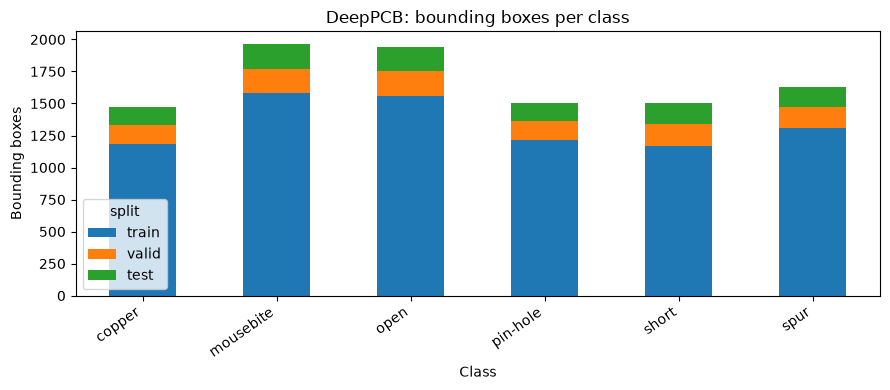

## PKU — inventory theo split

,dataset,split,images,labels,matched_pairs,images_without_label,labels_without_image,boxes,boxes_per_image
0,PKU,train,2772,2772,2772,0,0,11812,4.261
1,PKU,valid,366,366,366,0,0,1307,3.571
2,PKU,test,366,366,366,0,0,1307,3.571
3,PKU,TOTAL,3504,3504,3504,0,0,14426,4.117


**test:** ít box nhất = 1, nhiều nhất = 6 (tính cả ảnh 0 box).

,dataset,split,image,boxes
3175,PKU,test,data/raw/PKU-Market-PCB(Data enhanced version)...,1
3206,PKU,test,data/raw/PKU-Market-PCB(Data enhanced version)...,6
3394,PKU,test,data/raw/PKU-Market-PCB(Data enhanced version)...,6
3443,PKU,test,data/raw/PKU-Market-PCB(Data enhanced version)...,6
3449,PKU,test,data/raw/PKU-Market-PCB(Data enhanced version)...,6
3455,PKU,test,data/raw/PKU-Market-PCB(Data enhanced version)...,6


**train:** ít box nhất = 1, nhiều nhất = 6 (tính cả ảnh 0 box).

,dataset,split,image,boxes
148,PKU,train,data/raw/PKU-Market-PCB(Data enhanced version)...,1
149,PKU,train,data/raw/PKU-Market-PCB(Data enhanced version)...,1
150,PKU,train,data/raw/PKU-Market-PCB(Data enhanced version)...,1
151,PKU,train,data/raw/PKU-Market-PCB(Data enhanced version)...,1
272,PKU,train,data/raw/PKU-Market-PCB(Data enhanced version)...,6
273,PKU,train,data/raw/PKU-Market-PCB(Data enhanced version)...,6
274,PKU,train,data/raw/PKU-Market-PCB(Data enhanced version)...,6
275,PKU,train,data/raw/PKU-Market-PCB(Data enhanced version)...,6
1024,PKU,train,data/raw/PKU-Market-PCB(Data enhanced version)...,6


... (2 outputs left out)

**TOTAL:** ít box nhất = 1, nhiều nhất = 6 (tính cả ảnh 0 box).

,dataset,split,image,boxes
148,PKU,train,data/raw/PKU-Market-PCB(Data enhanced version)...,1
149,PKU,train,data/raw/PKU-Market-PCB(Data enhanced version)...,1
150,PKU,train,data/raw/PKU-Market-PCB(Data enhanced version)...,1
151,PKU,train,data/raw/PKU-Market-PCB(Data enhanced version)...,1
272,PKU,train,data/raw/PKU-Market-PCB(Data enhanced version)...,6
273,PKU,train,data/raw/PKU-Market-PCB(Data enhanced version)...,6
274,PKU,train,data/raw/PKU-Market-PCB(Data enhanced version)...,6
275,PKU,train,data/raw/PKU-Market-PCB(Data enhanced version)...,6
1024,PKU,train,data/raw/PKU-Market-PCB(Data enhanced version)...,6
2809,PKU,valid,data/raw/PKU-Market-PCB(Data enhanced version)...,1


### Bounding box theo class và split (chỉ class ID hợp lệ)

split,train,valid,test,total
class,,,,
Missing_hole,1988,223,223,2434
Mouse_bite,1968,221,221,2410
Open_circuit,1928,205,205,2338
Short,1964,216,216,2396
Spur,1952,217,217,2386
Spurious_copper,2012,225,225,2462


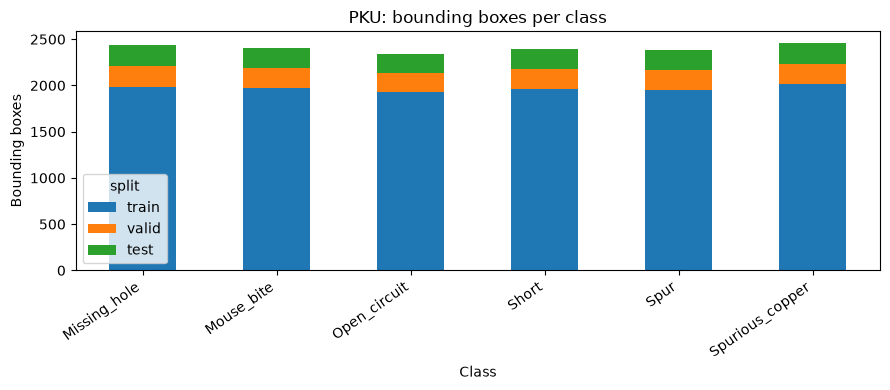

**Quy ước:** `boxes` là số dòng annotation không rỗng (kể cả dòng lỗi); bảng class chỉ tính dòng có class ID hợp lệ. Ảnh nhiều/ít box liệt kê tối đa 5 ảnh mỗi mức; box hợp lệ cho phân tích kích thước được lọc ở notebook 03.

Đã xuất `results/dataset_stats.csv`.

In [2]:
audits = all_audits()
for name, result in audits.items():
    display(Markdown(f'## {name} — inventory theo split'))
    summary = result['counts'].copy()
    summary['boxes_per_image'] = summary['boxes'] / summary['images'].replace(0, float('nan'))
    summary = pd.concat([summary, pd.DataFrame([{'dataset': name, 'split': 'TOTAL', **result['counts'].select_dtypes('number').sum().to_dict(), 'boxes_per_image': result['counts']['boxes'].sum() / result['counts']['images'].sum()}])], ignore_index=True)
    display(summary.round(3))
    for split, frame in list(result['per_image'].groupby('split')) + [('TOTAL', result['per_image'])]:
        display(Markdown(f'**{split}:** ít box nhất = {frame.boxes.min()}, nhiều nhất = {frame.boxes.max()} (tính cả ảnh 0 box).'))
        display(frame[frame.boxes.isin([frame.boxes.min(), frame.boxes.max()])].groupby('boxes').head(5))
    display(Markdown('### Bounding box theo class và split (chỉ class ID hợp lệ)'))
    table = result['by_class'].pivot(index='class', columns='split', values='boxes').reindex(columns=SPLITS).fillna(0).astype(int)
    table['total'] = table.sum(axis=1)
    display(table)
    ax = table[list(SPLITS)].plot.bar(stacked=True, figsize=(9, 4), title=f'{name}: bounding boxes per class')
    ax.set_ylabel('Bounding boxes')
    ax.set_xlabel('Class')
    plt.xticks(rotation=35, ha='right')
    plt.tight_layout()
    plt.show()
display(Markdown('**Quy ước:** `boxes` là số dòng annotation không rỗng (kể cả dòng lỗi); bảng class chỉ tính dòng có class ID hợp lệ. Ảnh nhiều/ít box liệt kê tối đa 5 ảnh mỗi mức; box hợp lệ cho phân tích kích thước được lọc ở notebook 03.'))
target = ROOT / 'results' / 'dataset_stats.csv'
if target.parent.is_dir():
    pd.concat([v['counts'].assign(boxes_per_image=lambda x: x.boxes / x.images.replace(0, float('nan'))) for v in audits.values()], ignore_index=True).to_csv(target, index=False)
    display(Markdown(f'Đã xuất `{target.relative_to(ROOT)}`.'))
else:
    display(Markdown('Chưa xuất results/dataset_stats.csv: results/ chưa có; cần được người dùng cho phép trước khi tạo thư mục.'))
